# Exercise: DeepInverse Basics

The goal of this exercise is to install and familiarize yourself with DeepInverse---a [PyTorch](https://pytorch.org/)-based library for solving imaging inverse problems with deep learning. In the following weeks, we will extensively use this library to learn how do use deep learning for inverse problems.

First check out the [DeepInverse website](https://deepinv.github.io/deepinv/index.html). The website provides you documentation of the library's Application Programming Interface (API) and many examples. Keep this as the main reference to understand the DeepInverse library.

## CPUs vs GPUs in Machine Learning

Before we start installing the library we need to briefly talk about CPUs vs GPUs and change the runtime type of this Google Colab. Machine Learning (ML) and in particular Deep Learning (DL) applications often rely on Graphics Processing Units (GPUs). These specialized chips excel at performing operations crucial for ML, such as matrix multiplications, much more efficiently than Central Processing Units (CPUs).

In ML, we train models (often deep neural networks) using data. For most practical applications, the size of the model and the dataset means that training on CPUs can be impractically slow, potentially preventing the model from reaching convergence in a reasonable timeframe. Therefore, GPUs are generally essential for efficient ML model training.

This is where tools like Google Colaboratory (Colab) become particularly useful. Colab offers free, albeit limited, access to GPUs in the Google Cloud directly through a Colab notebook. For the ML-focused exercises in this course, we will utilize Colab notebooks to take advantage of this GPU accessibility.


**TODO:** Click on `Runtime` in the colab top bar. Then click  on `Change runtime type` and select `T4GPU` or any other available hardware accelerators that are not `CPU`. This allows you to leverage GPUs or Tensor Processing Units (TPUs) specialized for ML operations.

## Installation

Now we will install the `deepinv` package. We can install latest stable version with the command

`pip install git+https://github.com/deepinv/deepinv.git#egg=deepinv   `

In a jupyter notebook you can execute shell commands with the prefix `!`.

Execute the cell below to install the `deepinv` library.

In [ ]:
!pip install git+https://github.com/deepinv/deepinv.git#egg=deepinv

  Cloning https://github.com/deepinv/deepinv.git to /tmp/pip-install-pm8sj2r2/deepinv_a11ddb8b29f443f5b3c4d71248fe8c8c
  Running command git clone --filter=blob:none --quiet https://github.com/deepinv/deepinv.git /tmp/pip-install-pm8sj2r2/deepinv_a11ddb8b29f443f5b3c4d71248fe8c8c
  Resolved https://github.com/deepinv/deepinv.git to commit 240721794eb1b5efa34dafdf582f3b39ff6e3dca
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 122.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 92.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 58.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.0 MB/s eta 0:00:00
   ━

Also install the following packages that we will use throughout this tutorial.

In [ ]:
!pip install bm3d # for classic bm3d denoiser
!pip install ptwt # for classic wavelet-based denoiser

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 862.0/862.0 kB 36.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.6/63.6 kB 5.2 MB/s eta 0:00:00


Let's important the necessary modules for this exercise.

In [ ]:
import time

import torch
import pandas as pd
import matplotlib.pyplot as plt

import deepinv as dinv
from deepinv.utils.plotting import plot_inset, plot
from deepinv.utils.demo import load_example

# Test
Next we will test if the library is correctly installed by running some code as specified in the [deepinv quickstart page](https://deepinv.github.io/deepinv/quickstart.html). The code solves an in-painting inverse problem (one tries to accurately "in-paint" masked out parts of the image). Don't worry for now  what the code exactly does as the purpose of this cell is to check if the library was correctly installed.


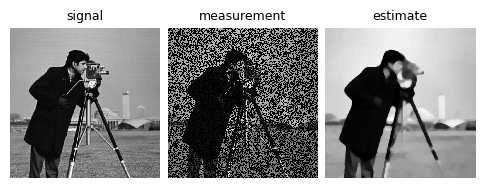

In [ ]:
import deepinv as dinv
from deepinv.utils import load_example
x = load_example("cameraman.png", img_size=512, grayscale=True, device='cpu')
physics = dinv.physics.Inpainting((1, 512, 512), mask = 0.5,
    noise_model=dinv.physics.GaussianNoise(sigma=0.01))
data_fidelity = dinv.optim.data_fidelity.L2()
prior = dinv.optim.prior.PnP(denoiser=dinv.models.MedianFilter())
model = dinv.optim.optim_builder(iteration="HQS", prior=prior, data_fidelity=data_fidelity,
                            params_algo={"stepsize": 1.0, "g_param": 0.1})
y = physics(x)
x_hat = model(y, physics)
dinv.utils.plot([x, y, x_hat], ["signal", "measurement", "estimate"], rescale_mode='clip')

# PyTorch
If the previous cell is running, you successfully installed the DeepInverse library. Since DeepInverse is a PyTorch-based library it is essential that you learn PyTorch fundamentals. PyTorch is the most popular deep learning library and most deep learning research uses PyTorch for deep learning.

Next, please work through the official PyTorch ["Learn the Basics"](https://docs.pytorch.org/tutorials/beginner/basics/intro.html) tutorial.

**Note:**  You can run each section of the PyTorch tutorial in a Google Colab (see the "Run in Google Colab" in the top bar in the tutorial section). This way you can actually interact and play with the code. We don't learn too much by just reading or just clicking through code cells.



# Check if GPU is available


Execute the cell below to check if a GPU is available. The cell should output `True`. If you see `False` you probably forgot to change the runtime type (click "Runtime" in top bar and select "Change runtime type" and select anything but "CPU").


In [ ]:
torch.cuda.is_available()

True

# Modeling the Physics of Inverse Problems: Forward Operators and Noise

Imaging inverse problems are described by the equation  $y=N(A(x))$ where $x$ is an unknown signal (image, volume, etc.) we want to recover, $y$, represents the observed measurements,
$A$ is a deterministic (linear or non-linear) operator (called the forward operator) capturing the physics of the acquisition and $N$ characterizes the noise affecting the measurements.


Typically we load first an image and then generate the measurements via `physics` that are implemented by the DeepInverse library.

```python
x = load_image()
y = physics(x) # simulate observation
```

The DeepInverse library implements many common forward operators and noise models and we will next work through a few examples from the official [DeepInverse Examples Page](https://deepinv.github.io/deepinv/auto_examples/basics/demo_physics_tour.html#sphx-glr-auto-examples-basics-demo-physics-tour-py).


### Let's load an image $x$ from the internet
We load an image from the [CBSD68 dataset](https://paperswithcode.com/dataset/cbsd68) (an image denoising benchmark dataset).

Selected GPU 0 with 15092 MiB free memory 
Using device cuda:0


<ipython-input-6-57b22880a949>:7: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x = torch.tensor(x, device=device, dtype=torch.float)


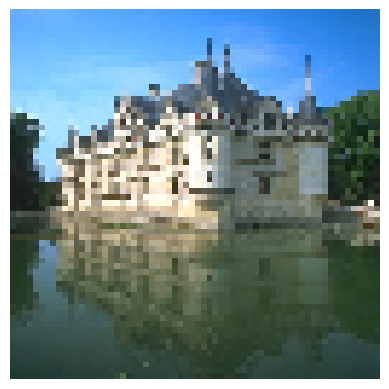

In [ ]:
device = dinv.utils.get_freer_gpu() if torch.cuda.is_available() else "cpu"

print(f'Using device {device}')

x = load_example("CBSD_0010.png", grayscale=False).to(device)

x = torch.tensor(x, device=device, dtype=torch.float)
x = torch.nn.functional.interpolate(x, size=(64, 64))
img_size = x.shape[1:]
# Set the global random seed from pytorch to ensure reproducibility of the example.
torch.manual_seed(0)

plt.imshow(x[0,:,:,:].cpu().permute(1,2,0))
plt.axis('off')
plt.show()

### Physics for Denoising
The denoising class `deepinv.physics.Denoising` is associated with an identity operator. In this example we choose a Poisson noise.

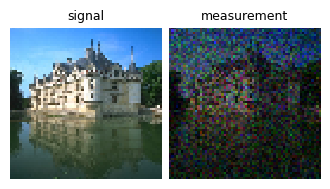

In [ ]:
# Define physics: idenitity + Poisson noise with rate 0.1
physics = dinv.physics.Denoising(dinv.physics.PoissonNoise(0.1))

y = physics(x)

# Plot results
plot([x, y], titles=["signal", "measurement"])

### Physics for Inpainting
"In-painting problems" try to correctly "in-paint" masked out pixels in the image.

The inpainting class `deepinv.physics.Inpainting` is associated with a mask operator. The mask is generated at random (unless an explicit mask is provided as input). We consider Gaussian noise in this example.




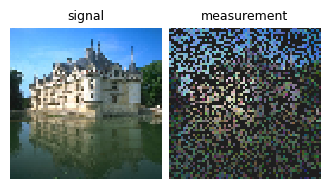

In [ ]:
sigma = 0.1  # Gaussian noise level
physics = dinv.physics.Inpainting(
    mask=0.5,
    tensor_size=x.shape[1:], # TODO: Check your understanding! Why do we need to pass the shape?
    noise_model=dinv.physics.GaussianNoise(sigma=sigma),
    device=device,
)

y = physics(x)

# Plot results
plot([x, y], titles=["signal", "measurement"])

### Physics for Demosaicing
The demosaicing class `deepinv.physics.Demosaicing` is associated with a Bayer pattern, which is a color filter array used in digital cameras (see [Wikipedia](https://en.wikipedia.org/wiki/Bayer_filter)).

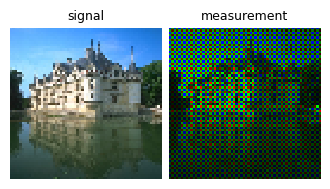

In [ ]:
physics = dinv.physics.Demosaicing(img_size=(64, 64), device=device)

y = physics(x)

# plot results
plot([x, y], titles=["signal", "measurement"])

### Physics of Compressed Sensing
The compressed sensing class `deepinv.physics.CompressedSensing` is associated with a random Gaussian matrix. Here we take `2048` measurements of an image of size `64x64`, which corresponds to a compression ratio of `2` (see [Wikipedia](https://en.wikipedia.org/wiki/Compressed_sensing) for more details on Compressed Sensing).

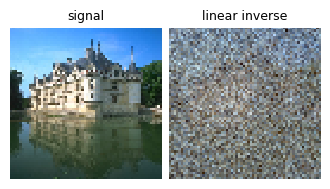

In [ ]:
physics = dinv.physics.CompressedSensing(
    m=2048,
    fast=False,
    channelwise=True,
    img_shape=img_size,
    compute_inverse=True,
    device=device,
)

y = physics(x)

# plot results
plot([x, physics.A_dagger(y)], titles=["signal", "linear inverse"])

### Physics of Computed Tomography
The class `deepinv.physics.Tomography` is associated with the sparse [Radon transform](https://en.wikipedia.org/wiki/Radon_transform). Here we take `20` views of an image of size `64x64`, and consider mixed Poisson-Gaussian noise.


We plot the original signal, the measurements (here a Sinogram), and the naive pseudo-inverse $A^\dagger$ (here a filtered backprojection).

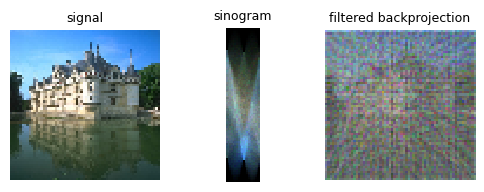

In [ ]:
physics = dinv.physics.Tomography(
    img_width=img_size[-1],
    angles=20,
    device=device,
    noise_model=dinv.physics.PoissonGaussianNoise(gain=0.1, sigma=0.05),
)

y = physics(x)

# Plot results
plot(
    [x, (y - y.min()) / y.max(), physics.A_dagger(y)], # NOTE: physics.A_dagger directly gives us the pseudo-inverse!
    titles=["signal", "sinogram", "filtered backprojection"],
)

### Physics of MRI
The class `deepinv.physics.MRI` is associated with a subsampling of the Fourier transform. The mask indicates which Fourier coefficients are measured. Here we use a random Cartesian mask, which corresponds to a compression ratio of approximately 4.

**Note:** The signal must be complex-valued for this operator, where the first channel corresponds to the real part and the second channel to the imaginary part. In this example, we set the imaginary part to zero.

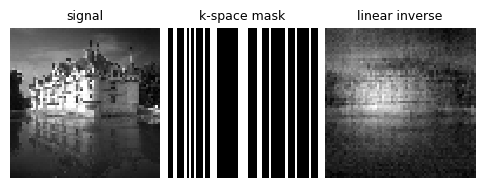

In [ ]:
mask = torch.rand((1, img_size[-1]), device=device) > 0.75
mask = torch.ones((img_size[-2], 1), device=device) * mask
mask[:, int(img_size[-1] / 2) - 2 : int(img_size[-1] / 2) + 2] = 1

physics = dinv.physics.MRI(
    mask=mask, device=device, noise_model=dinv.physics.GaussianNoise(sigma=0.05)
)

x2 = torch.cat(
    [x[:, 0, :, :].unsqueeze(1), torch.zeros_like(x[:, 0, :, :].unsqueeze(1))], dim=1
)
y = physics(x2)

# Plot results
signal = x2
k_space_mask = mask.unsqueeze(0).unsqueeze(0)
# Note we can get the Adjoint operator (here linear inverse) with physics.A_adjoint()
linear_inverse = physics.A_adjoint(y)
plot(
    [signal, k_space_mask, linear_inverse],
    titles=["signal", "k-space mask", "linear inverse"],
)

### Physics of Blur
The class `deepinv.physics.Blur` blurs the input image with a specified kernel. Here we use a Gaussian blur with a standard deviation of 2.


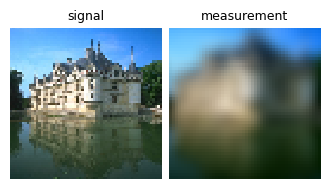

In [ ]:
physics = dinv.physics.Blur(
    dinv.physics.blur.gaussian_blur(sigma=(2, 2)), device=device
)

y = physics(x)

# plot results
plot([x, y], titles=["signal", "measurement"])

We can also specify an angle for anisotropic blurs. Play with the angle and standard deviations to get a feeling for the effects.

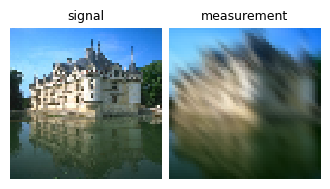

In [ ]:
physics = dinv.physics.Blur( # Pass angle to gaussian_blur
    dinv.physics.blur.gaussian_blur(sigma=(2, 0.1), angle=45.0), device=device
)

y = physics(x)

# plot results
plot([x, y], titles=["signal", "measurement"])

**Bonus:** Check out "[A tour of blur operators](https://deepinv.github.io/deepinv/auto_examples/basics/demo_blur_tour.html#sphx-glr-auto-examples-basics-demo-blur-tour-py)" for an in-depth tutorial on different blur operators and their implementations with DeepInverse.

### Physics of Super-Resolution
In super-resolution problems we observe a downsampled image and want to recover the original image of higher resolution.

In DeepInverse, the downsampling class `deepinv.physics.Downsampling` is associated with a downsampling operator.

Play with `factor` argument.

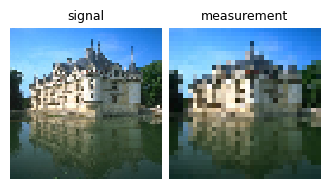

In [ ]:
# TODO: play with factor argument
physics = dinv.physics.Downsampling(img_size=img_size, factor=2, device=device)

# Downsample image
y = physics(x)

# Plot results
plot([x, y], titles=["signal", "measurement"])

# Denoisers

On the one hand, image denoising is conceptually the simplest class of inverse problems that we can think of as the forward operator is simply the identity operator.


On the other hand, denoisers happen to also be useful for  other inverse problems. For instance, we will use denoisers for the Plug and Play (PnP) algorithm later in the lecture.

To get more familiar with the DeepInverse library, we will dive into denoisers.

DeepInverse gives us access to many denoising methods and even pre-trained denoising models. Next, we will explore some denoising methods (classic methods and modern deep learning-based methods) with the DeepInverse library.

Load test images

In [ ]:
dtype = torch.float32
device = "cpu"
img_size = (173, 125)

image = load_example(
    "CBSD_0010.png", grayscale=False, device=device, dtype=dtype, img_size=img_size
)

# Next, set the global random seed from pytorch to ensure reproducibility of the example.
torch.manual_seed(0)
torch.cuda.manual_seed(0)

# Finally, create a noisy version of the image with a fixed noise level sigma.
sigma = 0.2
noisy_image = image + sigma * torch.randn_like(image)

We define a helper function to display comparisons of various restored images with their PSNR values (see [Wikipedia](https://en.wikipedia.org/wiki/Peak_signal-to-noise_ratio#:~:text=Peak%20signal%2Dto%2Dnoise%20ratio%20(PSNR)%20is%20an,the%20fidelity%20of%20its%20representation.) for an explanation of PSNR)  and zoom-in on a region of interest.

In [ ]:
def show_image_comparison(images, suptitle=None, ref=None):
    """Display various images restoration with PSNR and zoom-in"""

    titles = list(images.keys())
    if "Original" in images or ref is not None:
        # If the original image is in the dict, add PSNR in the titles.
        image = images["Original"] if "Original" in images else ref
        psnr = [dinv.metric.cal_psnr(image, im).item() for im in images.values()]
        titles = [
            f"{name} \n (PSNR: {psnr:.2f})" if name != "Original" else name
            for name, psnr in zip(images.keys(), psnr)
        ]
    # Plot the images with zoom-in
    fig = plot_inset(
        list(images.values()),
        titles=titles,
        extract_size=0.2,
        extract_loc=(0.5, 0.0),
        inset_size=0.5,
        return_fig=True,
        show=False,
        figsize=(len(images) * 1.5, 2.5),
    )

    # Add a suptitle if it is provided
    if suptitle:
        plt.suptitle(suptitle, size=12)
        plt.tight_layout()
        fig.subplots_adjust(top=0.85, bottom=0.02, left=0.02, right=0.95)
        plt.show()

### Classic denoisers
Classic denoisers are methods that don't learn from data and are typically motivated mathematically to remove noise. These methods were introduced before the "deep learning revolution".

DeepInv provides a set of classical denoisers such as [`deepinv.models.BM3D`](https://deepinv.github.io/deepinv/api/stubs/deepinv.models.BM3D.html#deepinv.models.BM3D), [`deepinv.models.TVDenoiser`](https://deepinv.github.io/deepinv/api/stubs/deepinv.models.TVDenoiser.html), [`deepinv.models.TGVDenoiser`](https://deepinv.github.io/deepinv/api/stubs/deepinv.models.TGVDenoiser.html#deepinv.models.TGVDenoiser), or [`deepinv.models.WaveletDictDenoiser`](https://deepinv.github.io/deepinv/api/stubs/deepinv.models.WaveletDictDenoiser.html#deepinv.models.WaveletDictDenoiser).

They can be easily used simply by instanciating their corresponding class, and calling them with the noisy image and the noise level.

**Note:** Feel free to study how these classic denoiser work. Some are more involved than others. You should at least look at the simple Total Variation (TV) denoiser (see [Wikipedia](https://en.wikipedia.org/wiki/Total_variation_denoising)) and understand how it works.

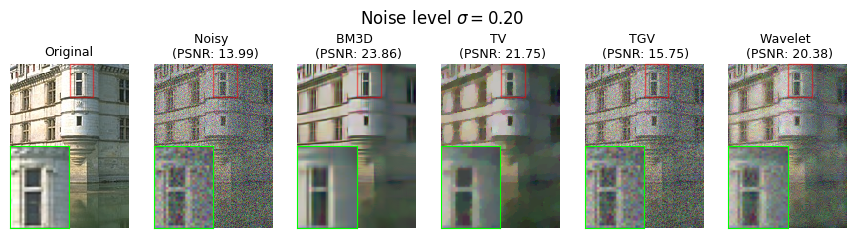

In [ ]:
bm3d = dinv.models.BM3D()
tv = dinv.models.TVDenoiser()
tgv = dinv.models.TGVDenoiser()
wavelet = dinv.models.WaveletDictDenoiser()

denoiser_results = {
    "Original": image,
    "Noisy": noisy_image,
    "BM3D": bm3d(noisy_image, sigma),
    "TV": tv(noisy_image, sigma),
    "TGV": tgv(noisy_image, sigma),
    "Wavelet": wavelet(noisy_image, sigma),
}
show_image_comparison(denoiser_results, suptitle=rf"Noise level $\sigma={sigma:.2f}$")

## Deep Denoisers
Deep Denoisers are denoising methods that use deep neural networks.

DeepInv also provides a set of deep denoisers. Most of these denoisers are available with pretrained weights, so they can be used readily. To instantiate them, you can simply call their corresponding class with default parameters and pretrained="download" to load their weights. You can then apply them by calling the model with the noisy image and the noise level.

**Note:** If you want to use deep learning you need to familarize yourself with important deep learning architectures. Start with understanding the basics of [MLPs](https://en.wikipedia.org/wiki/Multilayer_perceptron), [CNNs](https://en.wikipedia.org/wiki/Convolutional_neural_network),  [UNets](https://en.wikipedia.org/wiki/U-Net), and [Transformers](https://en.wikipedia.org/wiki/Transformer_(deep_learning_architecture)). The UNet is a particularly relevant architecture for imaging problems and was introduced by a research group in Freiburg, Germany in this [paper](https://arxiv.org/pdf/1505.04597). Another great way to familiarize yourself with the architectures is to read the papers that introduce the architectures. Below you can find the links to the papers in a comment next to the corresponding deep denoiser.

Downloading: "https://huggingface.co/deepinv/dncnn/resolve/main/dncnn_sigma2_color.pth?download=true" to /root/.cache/torch/hub/checkpoints/dncnn_sigma2_color.pth
100%|██████████| 2.56M/2.56M [00:00<00:00, 26.8MB/s]
Downloading: "https://huggingface.co/deepinv/drunet/resolve/main/drunet_deepinv_color_finetune_22k.pth?download=true" to /root/.cache/torch/hub/checkpoints/drunet_deepinv_color_finetune_22k.pth
100%|██████████| 125M/125M [00:01<00:00, 92.3MB/s]


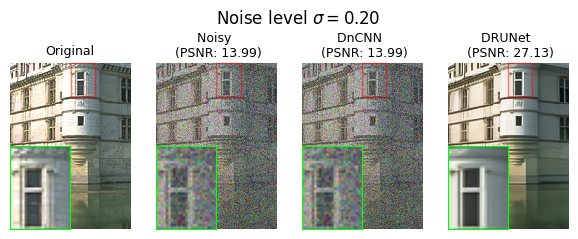

In [ ]:
dncnn = dinv.models.DnCNN() # CNN based (https://arxiv.org/abs/1608.03981)
drunet = dinv.models.DRUNet() # UNet based with convolution blocks (https://arxiv.org/abs/2008.13751)

# The two models below are transformer based denoisers but they need a lot of RAM
# so you may not be able to run them
#swinir = dinv.models.SwinIR() # Transformer based (https://arxiv.org/abs/2108.10257)
#scunet = dinv.models.SCUNet() # Unet based with transformer and convolution blocks (https://arxiv.org/abs/2203.13278)

denoiser_results = {
    "Original": image,
    "Noisy": noisy_image,
    "DnCNN": dncnn(noisy_image, sigma),
    "DRUNet": drunet(noisy_image, sigma),
    #"SCUNet": scunet(noisy_image, sigma),
    #"SwinIR": swinir(noisy_image, sigma),
}
show_image_comparison(denoiser_results, suptitle=rf"Noise level $\sigma={sigma:.2f}$")